## EN3160 Assignment 3

### A.H.T.M. Weerakoon

### 230689A

In [3]:
%pip install --upgrade certifi


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



     ---------------------------------------- 0.0/134.1 kB ? eta -:--:--
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     ------------------------- ----------- 92.2/134.1 kB 168.9 kB/s eta 0:00:01
     ------------------------- ----------- 92.

### Setup

In [4]:
import ssl, certifi, functools
ssl._create_default_https_context = functools.partial(ssl.create_default_context, cafile=certifi.where())
import os, time, copy, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models
from torchvision.models import ResNet18_Weights
%matplotlib inline

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available() else 'cpu')
NUM_WORKERS = 0      # 0 is safest in Jupyter (especially on Windows); raise to 2-4 on Linux for speed
torch.manual_seed(0); np.random.seed(0)
print('Device:', device)

Device: cuda


### Question 01

#### Data loading

In [5]:
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

100.0%


#### Network parameters

In [6]:
Din = 3 * 32 * 32      # input size
H = 100                # (a) hidden layer size
K = 10                 # classes

torch.manual_seed(0)
# Xavier-style initialisation: std 1e-5 (as in Listing 1) would make every sigmoid output 0.5
# and the gradient reaching W1 almost zero.
w1 = (torch.randn(Din, H) * np.sqrt(2.0 / (Din + H))).to(device)
b1 = torch.zeros(H, device=device)
w2 = (torch.randn(H, K) * np.sqrt(2.0 / (H + K))).to(device)
b2 = torch.zeros(K, device=device)

# Hyperparameters
epochs = 10            # (c)
lr = 0.05
lr_decay = 0.95
reg = 1e-4

def forward(x):
    h = torch.sigmoid(x.mm(w1) + b1)       # hidden layer
    s = h.mm(w2) + b2                      # class scores (logits)
    return h, s

def accuracy(loader):
    correct = total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1).to(device)
            _, s = forward(x)
            correct += (s.argmax(1).cpu() == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

#### Training loop

In [7]:
loss_history, epoch_loss, epoch_train_acc, epoch_test_acc = [], [], [], []

for t in range(epochs):
    running_loss, correct, seen = 0.0, 0, 0
    for inputs, labels in trainloader:
        N = inputs.shape[0]
        x = inputs.view(N, -1).to(device)
        labels = labels.to(device)
        y = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, s = forward(x)
        log_p = s - torch.logsumexp(s, dim=1, keepdim=True)        # numerically stable log-softmax
        p = log_p.exp()

        # (b) Cross-entropy loss + L2 regularisation
        loss = -(y * log_p).sum() / N + reg * (torch.sum(w1**2) + torch.sum(w2**2))
        loss_history.append(loss.item())
        running_loss += loss.item()
        correct += (s.argmax(1) == labels).sum().item(); seen += N

        # Backpropagation
        ds = (p - y) / N                        # dL/dS
        dw2 = h.t().mm(ds) + 2 * reg * w2
        db2 = ds.sum(dim=0)
        dh = ds.mm(w2.t())
        dz1 = dh * h * (1 - h)                  # sigmoid derivative
        dw1 = x.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1; b1 -= lr * db1
        w2 -= lr * dw2; b2 -= lr * db2

    epoch_loss.append(running_loss / len(trainloader))
    epoch_train_acc.append(100 * correct / seen)
    epoch_test_acc.append(accuracy(testloader))
    print(f'Epoch {t+1}/{epochs}  loss {epoch_loss[-1]:.4f}  '
          f'train acc {epoch_train_acc[-1]:.2f}%  test acc {epoch_test_acc[-1]:.2f}%')
    lr *= lr_decay

Epoch 1/10  loss 1.8534  train acc 36.08%  test acc 39.62%
Epoch 2/10  loss 1.7314  train acc 40.82%  test acc 41.62%
Epoch 3/10  loss 1.6834  train acc 42.71%  test acc 42.70%
Epoch 4/10  loss 1.6496  train acc 44.00%  test acc 43.24%
Epoch 5/10  loss 1.6220  train acc 45.23%  test acc 44.01%
Epoch 6/10  loss 1.5979  train acc 46.02%  test acc 44.51%
Epoch 7/10  loss 1.5769  train acc 46.81%  test acc 45.38%
Epoch 8/10  loss 1.5574  train acc 47.76%  test acc 45.65%
Epoch 9/10  loss 1.5389  train acc 48.44%  test acc 46.65%
Epoch 10/10  loss 1.5219  train acc 49.05%  test acc 46.29%


#### Plots and final accuracies

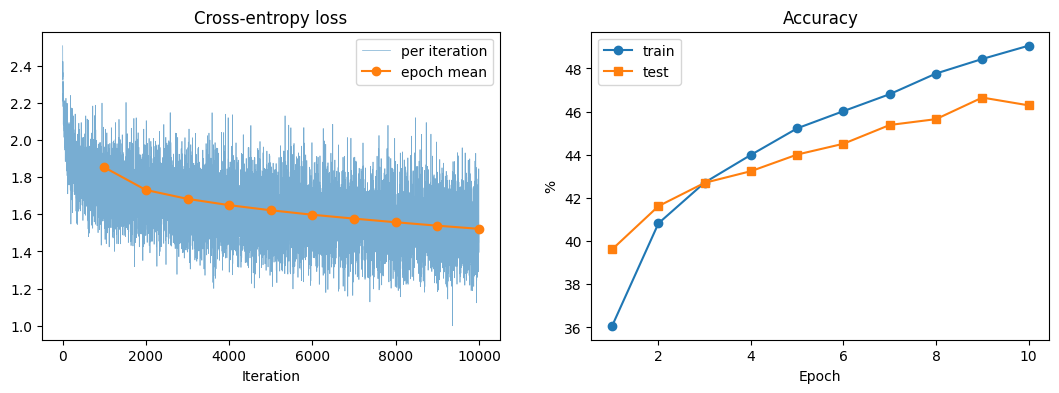

Training accuracy: 50.18%
Test accuracy:     46.29%


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(loss_history, lw=0.5, alpha=0.6, label='per iteration')
ax[0].plot(np.arange(1, epochs + 1) * len(trainloader), epoch_loss, 'o-', label='epoch mean')
ax[0].set_title('Cross-entropy loss'); ax[0].set_xlabel('Iteration'); ax[0].legend()
ax[1].plot(range(1, epochs + 1), epoch_train_acc, 'o-', label='train')
ax[1].plot(range(1, epochs + 1), epoch_test_acc, 's-', label='test')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('%'); ax[1].legend()
plt.show()

train_acc = accuracy(trainloader)
test_acc = accuracy(testloader)
print(f'Training accuracy: {train_acc:.2f}%')
print(f'Test accuracy:     {test_acc:.2f}%')